# Phase 3 Validation: Sentinel-2 → MNDWI → Otsu, zero-auth end-to-end

Proves the core detection pipeline works before any application code is built, per the project's Phase 3 request.

**Everything below hits real, live services** — no mocked data:
- Search: Microsoft Planetary Computer STAC API (`planetarycomputer.microsoft.com/api/stac/v1`), anonymous.
- Pixel access: Planetary Computer SAS-sign endpoint (anonymous) → signed HTTPS URL → windowed read via `rasterio`.
- No account, no API key, no OAuth flow anywhere in this notebook.

Test location: **Pallikaranai Marsh, Chennai, India** (candidate test location #1, see `docs/09-test-locations.md`), bbox `[80.19, 12.90, 80.23, 12.95]`.


In [1]:
import json
import urllib.request
import urllib.parse

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
from scipy.ndimage import zoom
from skimage.filters import threshold_otsu

PC_STAC = "https://planetarycomputer.microsoft.com/api/stac/v1/search"
PC_SIGN = "https://planetarycomputer.microsoft.com/api/sas/v1/sign"

BBOX = [80.19, 12.90, 80.23, 12.95]  # Pallikaranai Marsh, Chennai
DATETIME_RANGE = "2023-11-01/2024-02-28"  # dry-season window, per docs/03-detection-methodology.md


## 1. Anonymous STAC search + metadata-only scene selection

Filters by `eo:cloud_cover` from the search response itself — no pixels downloaded yet.

In [2]:
def stac_search(bbox, datetime_range, max_cloud=40, limit=10):
    params = {
        "collections": "sentinel-2-l2a",
        "bbox": ",".join(map(str, bbox)),
        "datetime": datetime_range,
        "limit": limit,
    }
    url = PC_STAC + "?" + urllib.parse.urlencode(params)
    req = urllib.request.Request(url, headers={"Accept": "application/geo+json"})
    with urllib.request.urlopen(req, timeout=30) as r:
        d = json.load(r)
    feats = d.get("features", [])
    feats = [f for f in feats if f["properties"].get("eo:cloud_cover", 100) <= max_cloud]
    feats.sort(key=lambda f: f["properties"].get("eo:cloud_cover", 100))
    return feats


feats = stac_search(BBOX, DATETIME_RANGE)
print(f"{len(feats)} usably-clear scene(s) found (<=40% cloud) for {DATETIME_RANGE}")
for f in feats:
    p = f["properties"]
    print(f"  {f['id']}  cloud={p.get('eo:cloud_cover'):.1f}%  date={p['datetime']}")

best = feats[0]
print("\nSelected scene:", best["id"])


9 usably-clear scene(s) found (<=40% cloud) for 2023-11-01/2024-02-28
  S2A_MSIL2A_20240204T050011_R119_T44PMV_20240204T091031  cloud=5.0%  date=2024-02-04T05:00:11.024000Z
  S2B_MSIL2A_20240209T045949_R119_T44PMV_20240209T092438  cloud=10.6%  date=2024-02-09T04:59:49.024000Z
  S2A_MSIL2A_20240224T045811_R119_T44PMV_20240224T100911  cloud=12.3%  date=2024-02-24T04:58:11.024000Z
  S2A_MSIL2A_20240115T050141_R119_T44PMV_20240115T081416  cloud=14.3%  date=2024-01-15T05:01:41.024000Z
  S2A_MSIL2A_20240214T045911_R119_T44PMV_20240214T091808  cloud=16.4%  date=2024-02-14T04:59:11.024000Z
  S2B_MSIL2A_20240130T050039_R119_T44PMV_20240130T081630  cloud=17.0%  date=2024-01-30T05:00:39.024000Z
  S2A_MSIL2A_20240125T050101_R119_T44PMV_20240125T091621  cloud=26.5%  date=2024-01-25T05:01:01.024000Z
  S2B_MSIL2A_20240219T045839_R119_T44PMV_20240219T081659  cloud=28.3%  date=2024-02-19T04:58:39.024000Z
  S2B_MSIL2A_20240110T050159_R119_T44PMV_20240110T091521  cloud=35.1%  date=2024-01-10T05:01:59.024

## 2. Sign asset URLs (anonymous) and read only the AOI window

`rasterio` range-reads just the bbox window from the remote COG — no full-scene download.

In [3]:
def sign(href):
    url = PC_SIGN + "?href=" + urllib.parse.quote(href, safe="")
    with urllib.request.urlopen(url, timeout=30) as r:
        return json.load(r)["href"]


def read_window(signed_href, bbox):
    with rasterio.open(signed_href) as src:
        b = transform_bounds("EPSG:4326", src.crs, *bbox)
        window = from_bounds(*b, transform=src.transform)
        arr = src.read(1, window=window).astype("float32")
        return arr


green_href = sign(best["assets"]["B03"]["href"])  # 10m
swir_href = sign(best["assets"]["B11"]["href"])   # 20m
scl_href = sign(best["assets"]["SCL"]["href"])    # 20m

green = read_window(green_href, BBOX)
swir_raw = read_window(swir_href, BBOX)
scl_raw = read_window(scl_href, BBOX)

print("green (B03) shape:", green.shape)
print("swir (B11) shape :", swir_raw.shape)
print("scl shape        :", scl_raw.shape)


green (B03) shape: (554, 436)
swir (B11) shape : (277, 218)
scl shape        : (277, 218)


## 3. Resample 20m bands to 10m grid, compute MNDWI, mask clouds via SCL

In [4]:
def resample_to(arr, target_shape):
    if arr.shape == target_shape:
        return arr
    zy = target_shape[0] / arr.shape[0]
    zx = target_shape[1] / arr.shape[1]
    return zoom(arr, (zy, zx), order=0)


swir = resample_to(swir_raw, green.shape)
scl = resample_to(scl_raw, green.shape)

denom = green + swir
mndwi = np.where(denom == 0, 0, (green - swir) / np.where(denom == 0, 1, denom))

# SCL classes to exclude: 0 nodata, 1 saturated, 2 dark/shadow, 3 cloud shadow,
# 7 unclassified, 8/9 cloud med/high, 10 cirrus, 11 snow (per docs/03-detection-methodology.md)
EXCLUDE_CLASSES = [0, 1, 2, 3, 7, 8, 9, 10, 11]
cloud_mask = np.isin(scl, EXCLUDE_CLASSES)
valid = ~cloud_mask

print(f"valid (non-cloud/shadow) pixel fraction: {valid.mean():.2%}")
print(f"MNDWI range over valid pixels: [{mndwi[valid].min():.3f}, {mndwi[valid].max():.3f}]")


valid (non-cloud/shadow) pixel fraction: 58.16%
MNDWI range over valid pixels: [-0.467, 0.337]


## 4. Otsu threshold (scene-adaptive, not a fixed cutoff) → binary water mask

In [5]:
valid_pixels = mndwi[valid]
thresh = threshold_otsu(valid_pixels)
water_mask = (mndwi > thresh) & valid
water_frac = water_mask.sum() / valid.sum()

print(f"Otsu threshold: {thresh:.4f}")
print(f"Water fraction of clear pixels: {water_frac:.2%}")
print(f"Scene: {best['id']}  date: {best['properties']['datetime']}  cloud%: {best['properties'].get('eo:cloud_cover'):.1f}")


Otsu threshold: -0.1642
Water fraction of clear pixels: 38.18%
Scene: S2A_MSIL2A_20240204T050011_R119_T44PMV_20240204T091031  date: 2024-02-04T05:00:11.024000Z  cloud%: 5.0


## 5. Visualize: MNDWI histogram (with Otsu cut) + water mask overlay

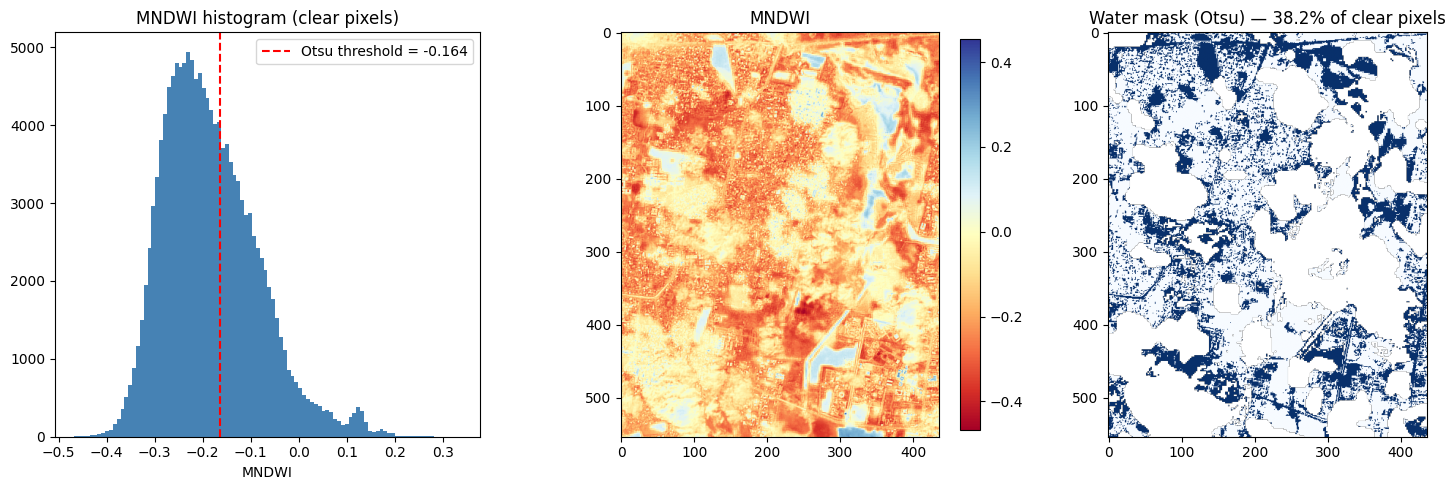

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].hist(valid_pixels, bins=100, color="steelblue")
axes[0].axvline(thresh, color="red", linestyle="--", label=f"Otsu threshold = {thresh:.3f}")
axes[0].set_title("MNDWI histogram (clear pixels)")
axes[0].set_xlabel("MNDWI")
axes[0].legend()

im1 = axes[1].imshow(mndwi, cmap="RdYlBu")
axes[1].set_title("MNDWI")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

axes[2].imshow(np.where(valid, water_mask.astype(float), np.nan), cmap="Blues", vmin=0, vmax=1)
axes[2].set_title(f"Water mask (Otsu) — {water_frac:.1%} of clear pixels")

plt.tight_layout()
plt.savefig("pallikaranai_mndwi_validation.png", dpi=110)
plt.show()


## Result

This confirms the full MVP pipeline — anonymous STAC search, anonymous SAS-signed pixel access, windowed
read, MNDWI, SCL cloud masking, Otsu thresholding — works end-to-end against live data with **zero
accounts, zero API keys**. See `docs/research-log.md` for the equivalent verification against the
Manila Bay candidate location, including a case where an initial bbox guess turned out too coarse
(open bay water dominates, no visible year-to-year transition) — a real finding from actually running
this pipeline, not a hypothetical risk.
